# CSU faculty pay by department (2024)

Compare **total pay excluding benefits** by scraped department, retaining departments
with **at least 10 valid pay observations after filtering**. Median pay is the primary
ranking because very large payments can pull the mean upward; both are reported.

Only total pay of **$40,000 or more** is included. Settings below control the pay
measure, minimum pay, and minimum sample size.
Identical department labels are pooled across campuses; differently named departments
(for example, “Accounting” and “Accountancy”) remain separate. Whitespace is normalized.
Missing labels and the scrape artifact `Index.Php` are excluded. Only fully identical
joined rows are deduplicated; the source parquet is unchanged.

**Interpretation:** observations are joined payroll rows, not necessarily unique people
or full-time annual salaries. The source join uses names and can contain ambiguous matches
and repeated appointments. Lecturer/professor mix, workload, partial-year employment,
campus mix, and department-label quality can affect rankings. These describe recorded
pay in the matched data, not an adjusted comparison of salary rates.


In [8]:
from pathlib import Path
import math
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MaxNLocator
from IPython.display import display

PAY_COL = "totalpay"  # Alternatives: "base", "totalpaybenefits"
MIN_PAY = 40_000
MIN_OBSERVATIONS = 10
TOP_N = 10
HISTOGRAMS_PER_PAGE = 24
INVALID_DEPARTMENT_LABELS = {"index.php"}

# Works from this folder, its subfolders, or the repository root.
candidates = [
    parent / relative
    for parent in (Path.cwd(), *Path.cwd().parents)
    for relative in ("Data/csu_joined_pay.parquet",
                     "CSC4693/Faculty/Data/csu_joined_pay.parquet")
]
data_path = next((path for path in candidates if path.is_file()), None)
if data_path is None:
    raise FileNotFoundError("Could not locate Data/csu_joined_pay.parquet")
raw = pd.read_parquet(data_path)
pay_labels = {"totalpay": "Total pay (excluding benefits)",
              "base": "Base pay", "totalpaybenefits": "Total pay + benefits"}
pay_label = pay_labels.get(PAY_COL, PAY_COL)
print(f"Loaded {len(raw):,} joined rows from {data_path.name}")


Loaded 15,501 joined rows from csu_joined_pay.parquet


In [9]:
df = raw.drop_duplicates().copy()
exact_duplicates_removed = len(raw) - len(df)
df["department"] = (df["department_scraped"].astype("string")
                    .str.replace(r"\s+", " ", regex=True).str.strip())
df["pay"] = pd.to_numeric(df[PAY_COL], errors="coerce")
valid_department = (
    df["department"].notna()
    & df["department"].ne("")
    & ~df["department"].str.casefold().isin(INVALID_DEPARTMENT_LABELS)
).fillna(False)
valid_pay = df["pay"].notna() & np.isfinite(df["pay"])
valid_pay &= df["pay"].ge(MIN_PAY)
clean = df.loc[valid_department & valid_pay].copy()

summary = (clean.groupby("department")["pay"]
           .agg(n="count", median_pay="median", mean_pay="mean",
                min_pay="min", max_pay="max")
           .query("n >= @MIN_OBSERVATIONS")
           .sort_values(["median_pay", "mean_pay"], ascending=False))
plot_data = clean.loc[clean["department"].isin(summary.index)].copy()
if summary.empty:
    raise ValueError("No departments meet the selected filters.")
years = ", ".join(map(str, sorted(plot_data["year_transparentCA"].unique())))
pay_filter_note = f"Pay >= ${MIN_PAY:,.0f}"
print(f"Payroll year(s): {years}; {pay_label}; {pay_filter_note}")
print(f"Removed {exact_duplicates_removed:,} fully identical joined rows.")
print(f"Excluded {int((~valid_department).sum()):,} missing/invalid department rows.")
print(f"Excluded {int((valid_department & ~valid_pay).sum()):,} further rows by pay filter.")
print(f"Eligible: {len(summary):,} departments, {len(plot_data):,} observations "
      f"(minimum {MIN_OBSERVATIONS} per department).")
print(f"Threshold excludes {len(clean) - len(plot_data):,} further observations.")


Payroll year(s): 2024; Total pay (excluding benefits); Pay >= $40,000
Removed 435 fully identical joined rows.
Excluded 579 missing/invalid department rows.
Excluded 7,033 further rows by pay filter.
Eligible: 179 departments, 6,126 observations (minimum 10 per department).
Threshold excludes 1,328 further observations.


## Highest and lowest median pay

Sample sizes count the observations used in both the rankings and histograms.
The complete ranking is available as `summary` (highest median first).


Highest 10 departments by median pay


,department,n,median_pay,mean_pay,min_pay,max_pay
0,Finance,52,"$179,217.32","$170,761.23","$40,898.31","$232,842.96"
1,Accounting and Finance,45,"$173,881.64","$156,285.77","$47,800.27","$227,229.13"
2,Accountancy,25,"$173,498.90","$172,395.46","$42,748.31","$277,660.29"
3,Management Information Systems,23,"$171,436.00","$151,661.11","$47,127.22","$235,115.20"
4,International Business & Marketing,16,"$170,452.82","$158,087.92","$68,651.60","$289,634.52"
5,"Info Systems, Finance&Account",18,"$169,205.52","$166,322.44","$76,820.50","$246,900.92"
6,Accounting,65,"$167,699.86","$163,358.50","$40,392.80","$304,150.29"
7,Information Systems and Decision Sciences,24,"$166,717.72","$155,375.81","$50,612.00","$226,039.76"
8,"Finance, Real Estate, and Law",12,"$166,347.06","$144,132.30","$40,105.52","$191,606.28"
9,Decision Sciences,11,"$163,916.09","$160,896.51","$119,884.64","$227,902.24"


Lowest 10 departments by median pay


,department,n,median_pay,mean_pay,min_pay,max_pay
0,Cinematic Arts,14,"$65,569.48","$71,537.86","$43,172.74","$110,630.99"
1,Teacher Education and Foundation,29,"$67,833.02","$79,916.01","$44,267.95","$146,277.20"
2,Cinematic Arts & Technology,10,"$74,248.89","$89,171.44","$60,538.57","$130,431.05"
3,Dual Language and English Learner Education,10,"$75,445.78","$82,700.10","$52,186.38","$136,829.37"
4,Department of Nutrition and Food Science,21,"$75,548.24","$79,488.85","$41,215.83","$122,601.69"
5,Humanities & Communication,31,"$77,101.05","$81,899.23","$41,460.22","$191,684.51"
6,Social Sciences & Global Studi,10,"$77,409.60","$85,245.41","$45,372.94","$132,363.37"
7,Department of Apparel Merchandising and Manage...,12,"$78,067.46","$73,832.22","$43,220.34","$128,107.57"
8,Art + Film,16,"$78,542.52","$86,027.52","$44,216.53","$161,361.98"
9,Mathematics Statistics,65,"$79,255.29","$88,820.54","$40,739.79","$147,671.27"


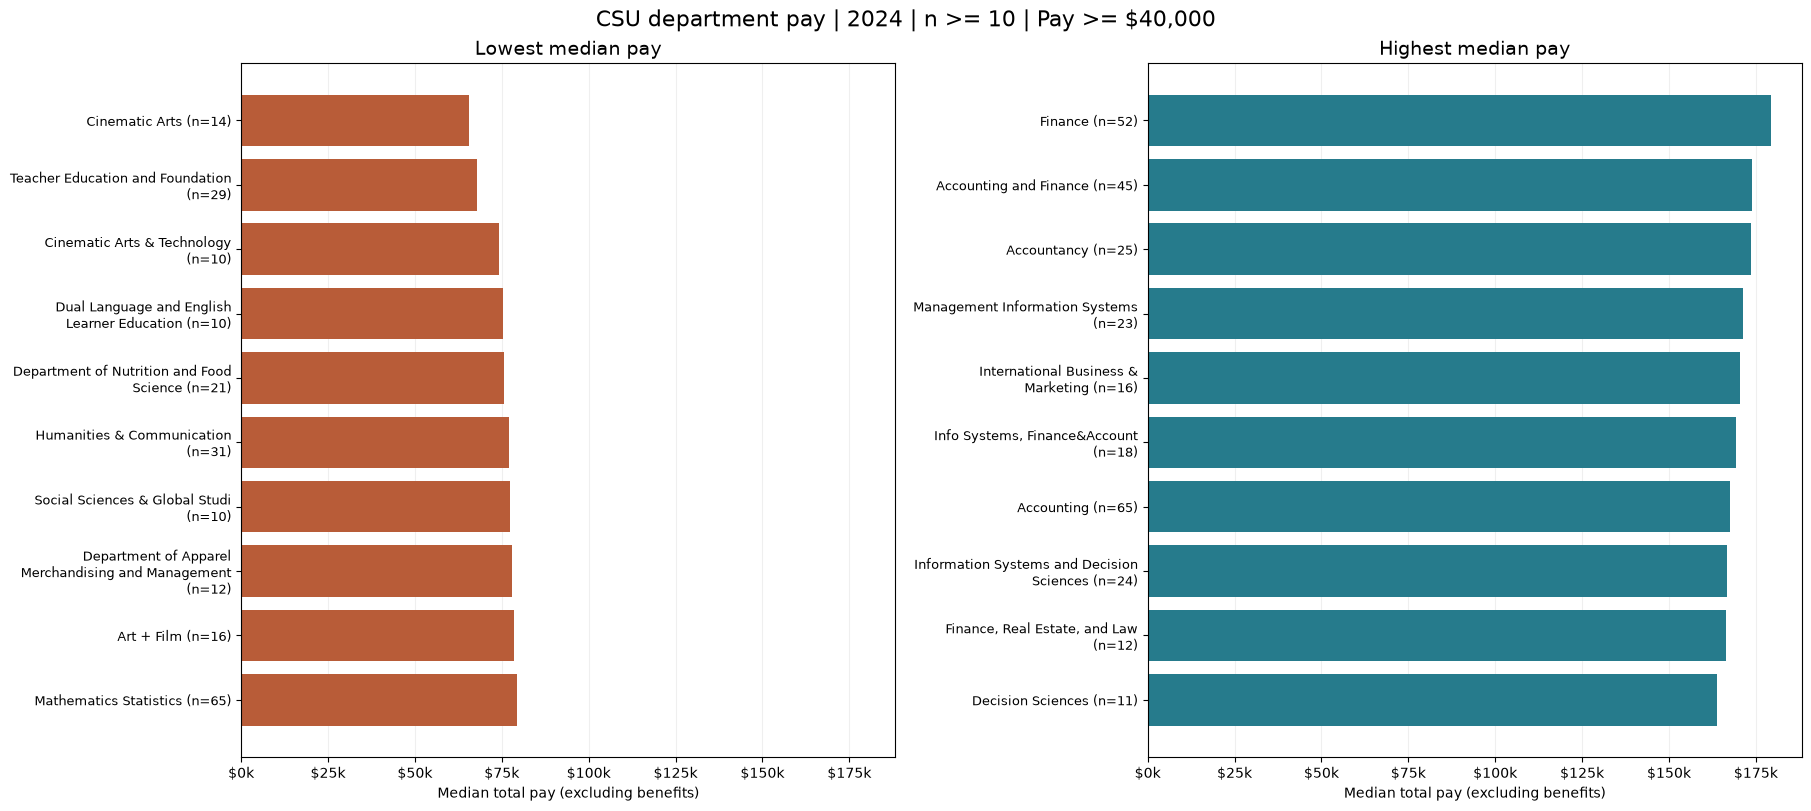

In [10]:
def show_pay_table(table):
    formatted = table.reset_index().copy()
    for column in ["median_pay", "mean_pay", "min_pay", "max_pay"]:
        formatted[column] = formatted[column].map(lambda value: f"${value:,.2f}")
    display(formatted)

print(f"Highest {min(TOP_N, len(summary))} departments by median pay")
show_pay_table(summary.head(TOP_N))
print(f"Lowest {min(TOP_N, len(summary))} departments by median pay")
show_pay_table(summary.sort_values(["median_pay", "mean_pay"]).head(TOP_N))

fig, axes = plt.subplots(1, 2, figsize=(18, 8), layout="constrained", sharex=True)
for ax, table, title, color in [
    (axes[0], summary.sort_values(["median_pay", "mean_pay"]).head(TOP_N),
     "Lowest median pay", "#b85c38"),
    (axes[1], summary.head(TOP_N), "Highest median pay", "#267b8c"),
]:
    labels = [textwrap.fill(f"{name} (n={row.n:,.0f})", 32)
              for name, row in table.iterrows()]
    ax.barh(range(len(table)), table["median_pay"], color=color)
    ax.set_yticks(range(len(table)), labels, fontsize=9)
    ax.invert_yaxis()
    ax.set_title(title, fontsize=14)
    ax.set_xlabel(f"Median {pay_label.lower()}")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"${value / 1000:,.0f}k"))
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle(f"CSU department pay | {years} | n >= {MIN_OBSERVATIONS} | {pay_filter_note}", fontsize=16)
plt.show()


## Pay histograms for every eligible department

Each panel shows the distribution of individual observed pay amounts. Panels are ordered
from highest to lowest median and split across pages for readability. All use the same
dollar bins and x-axis range, including the full observed range. Y-axis counts vary by
panel so smaller departments remain readable. A dashed line marks the department median.


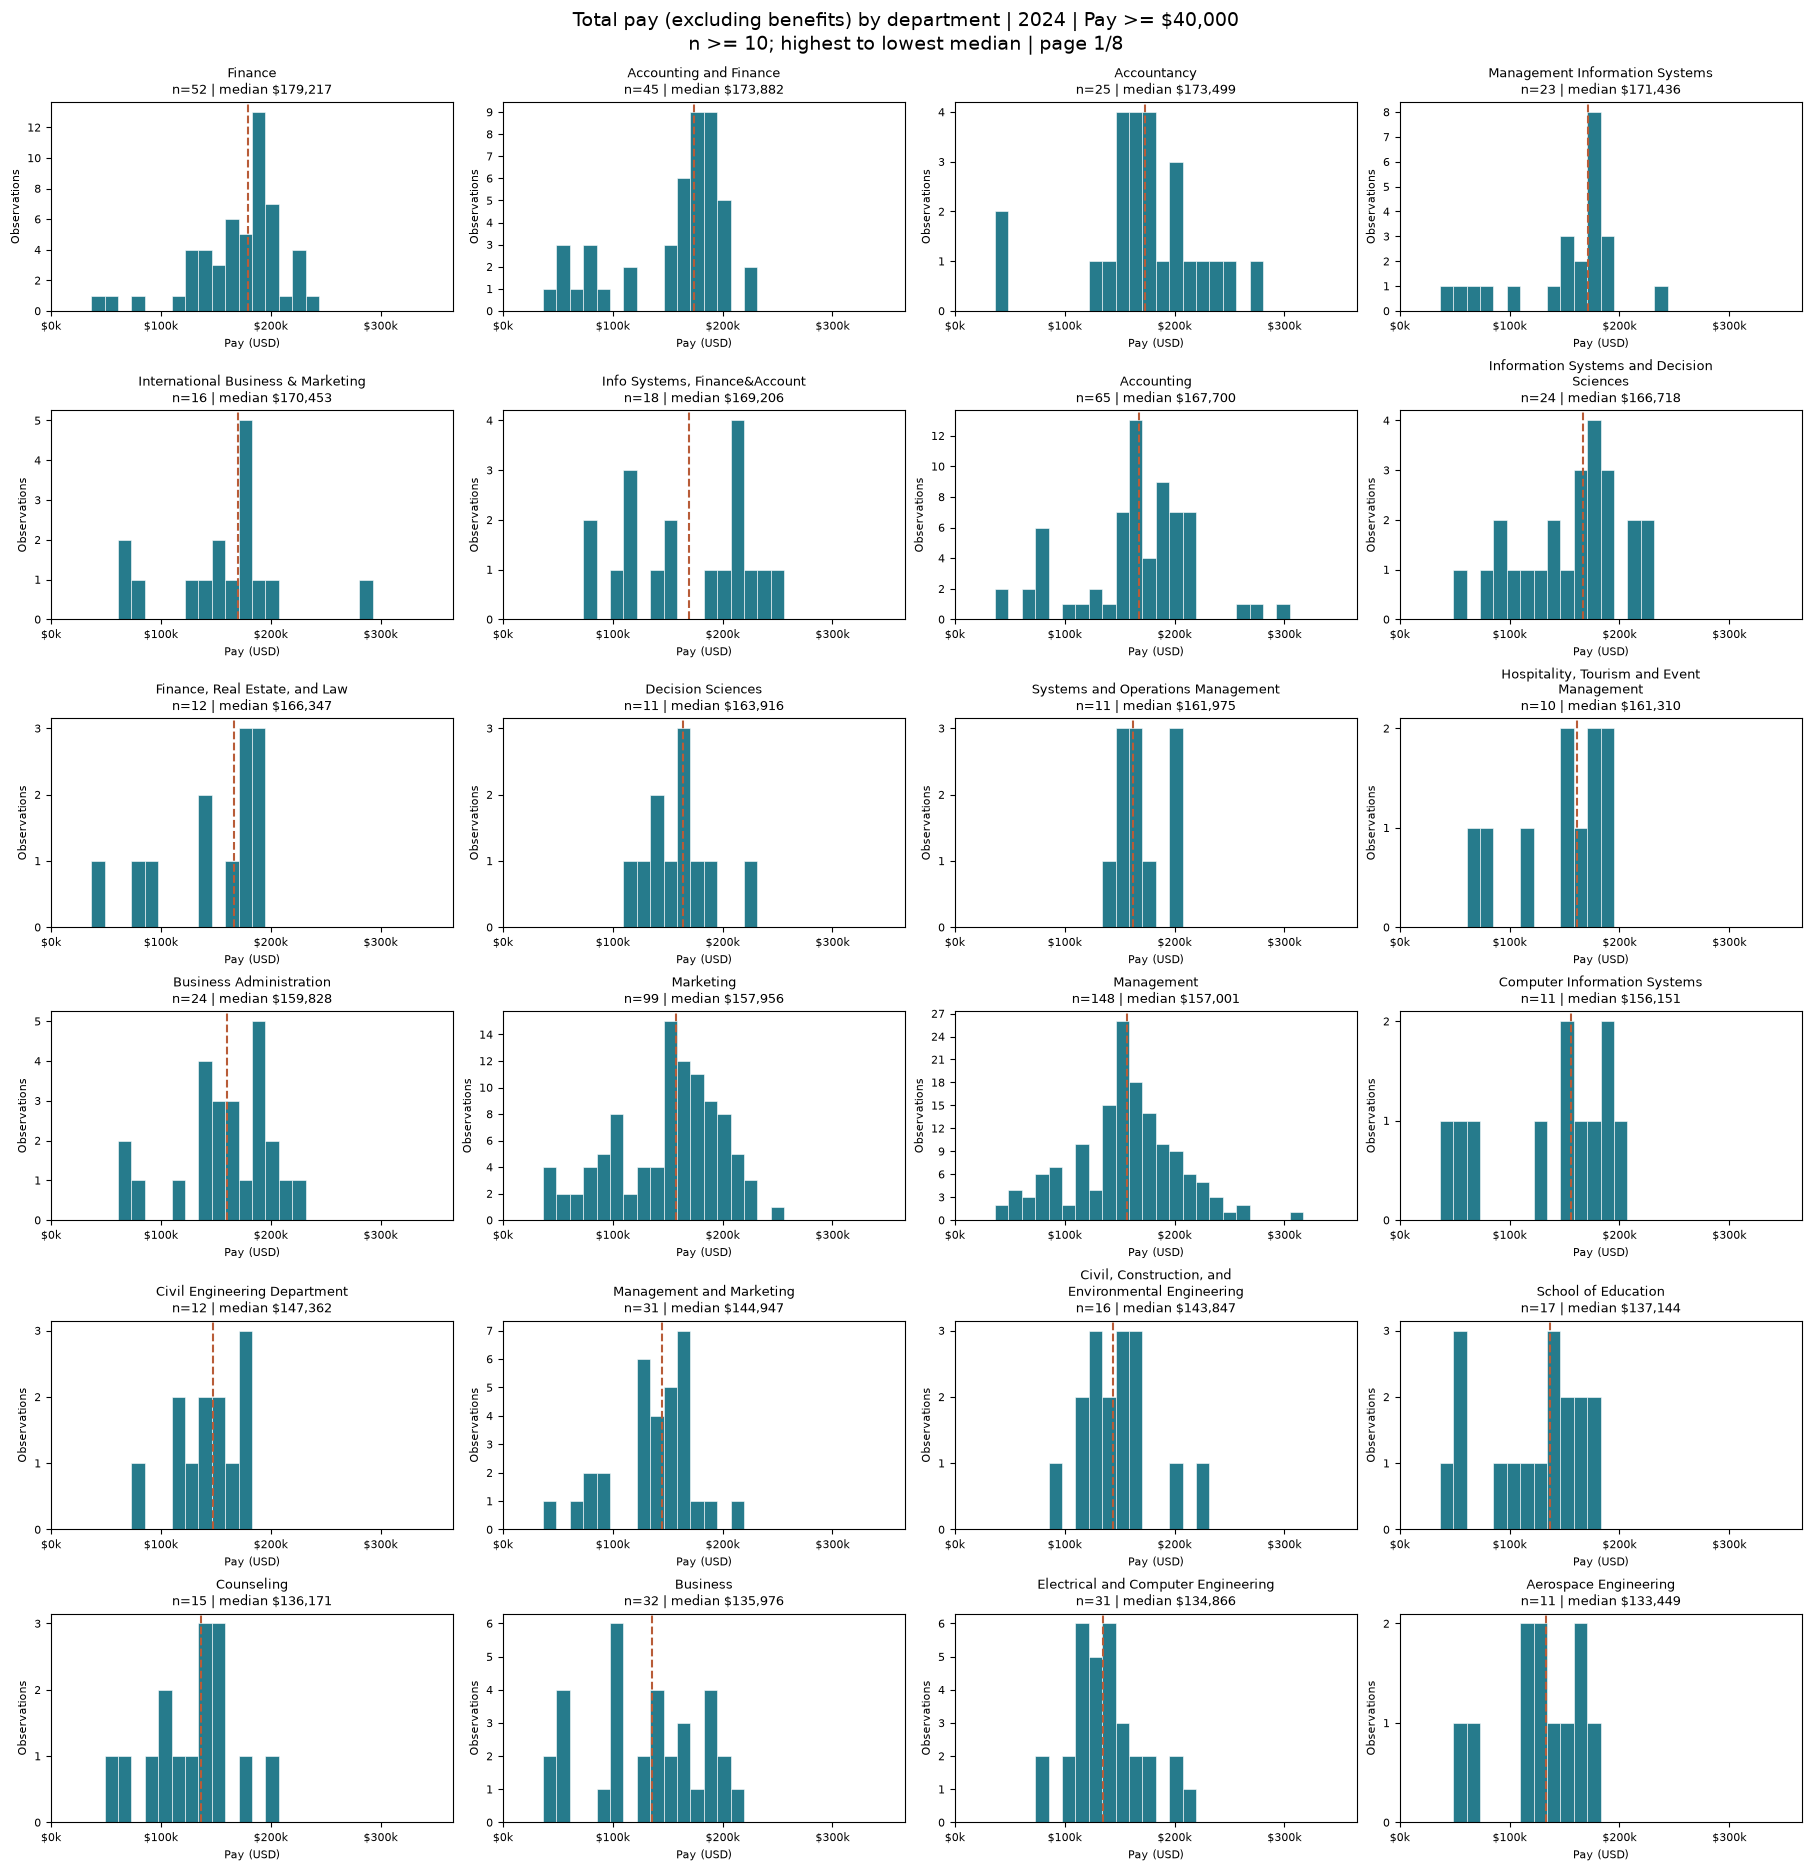

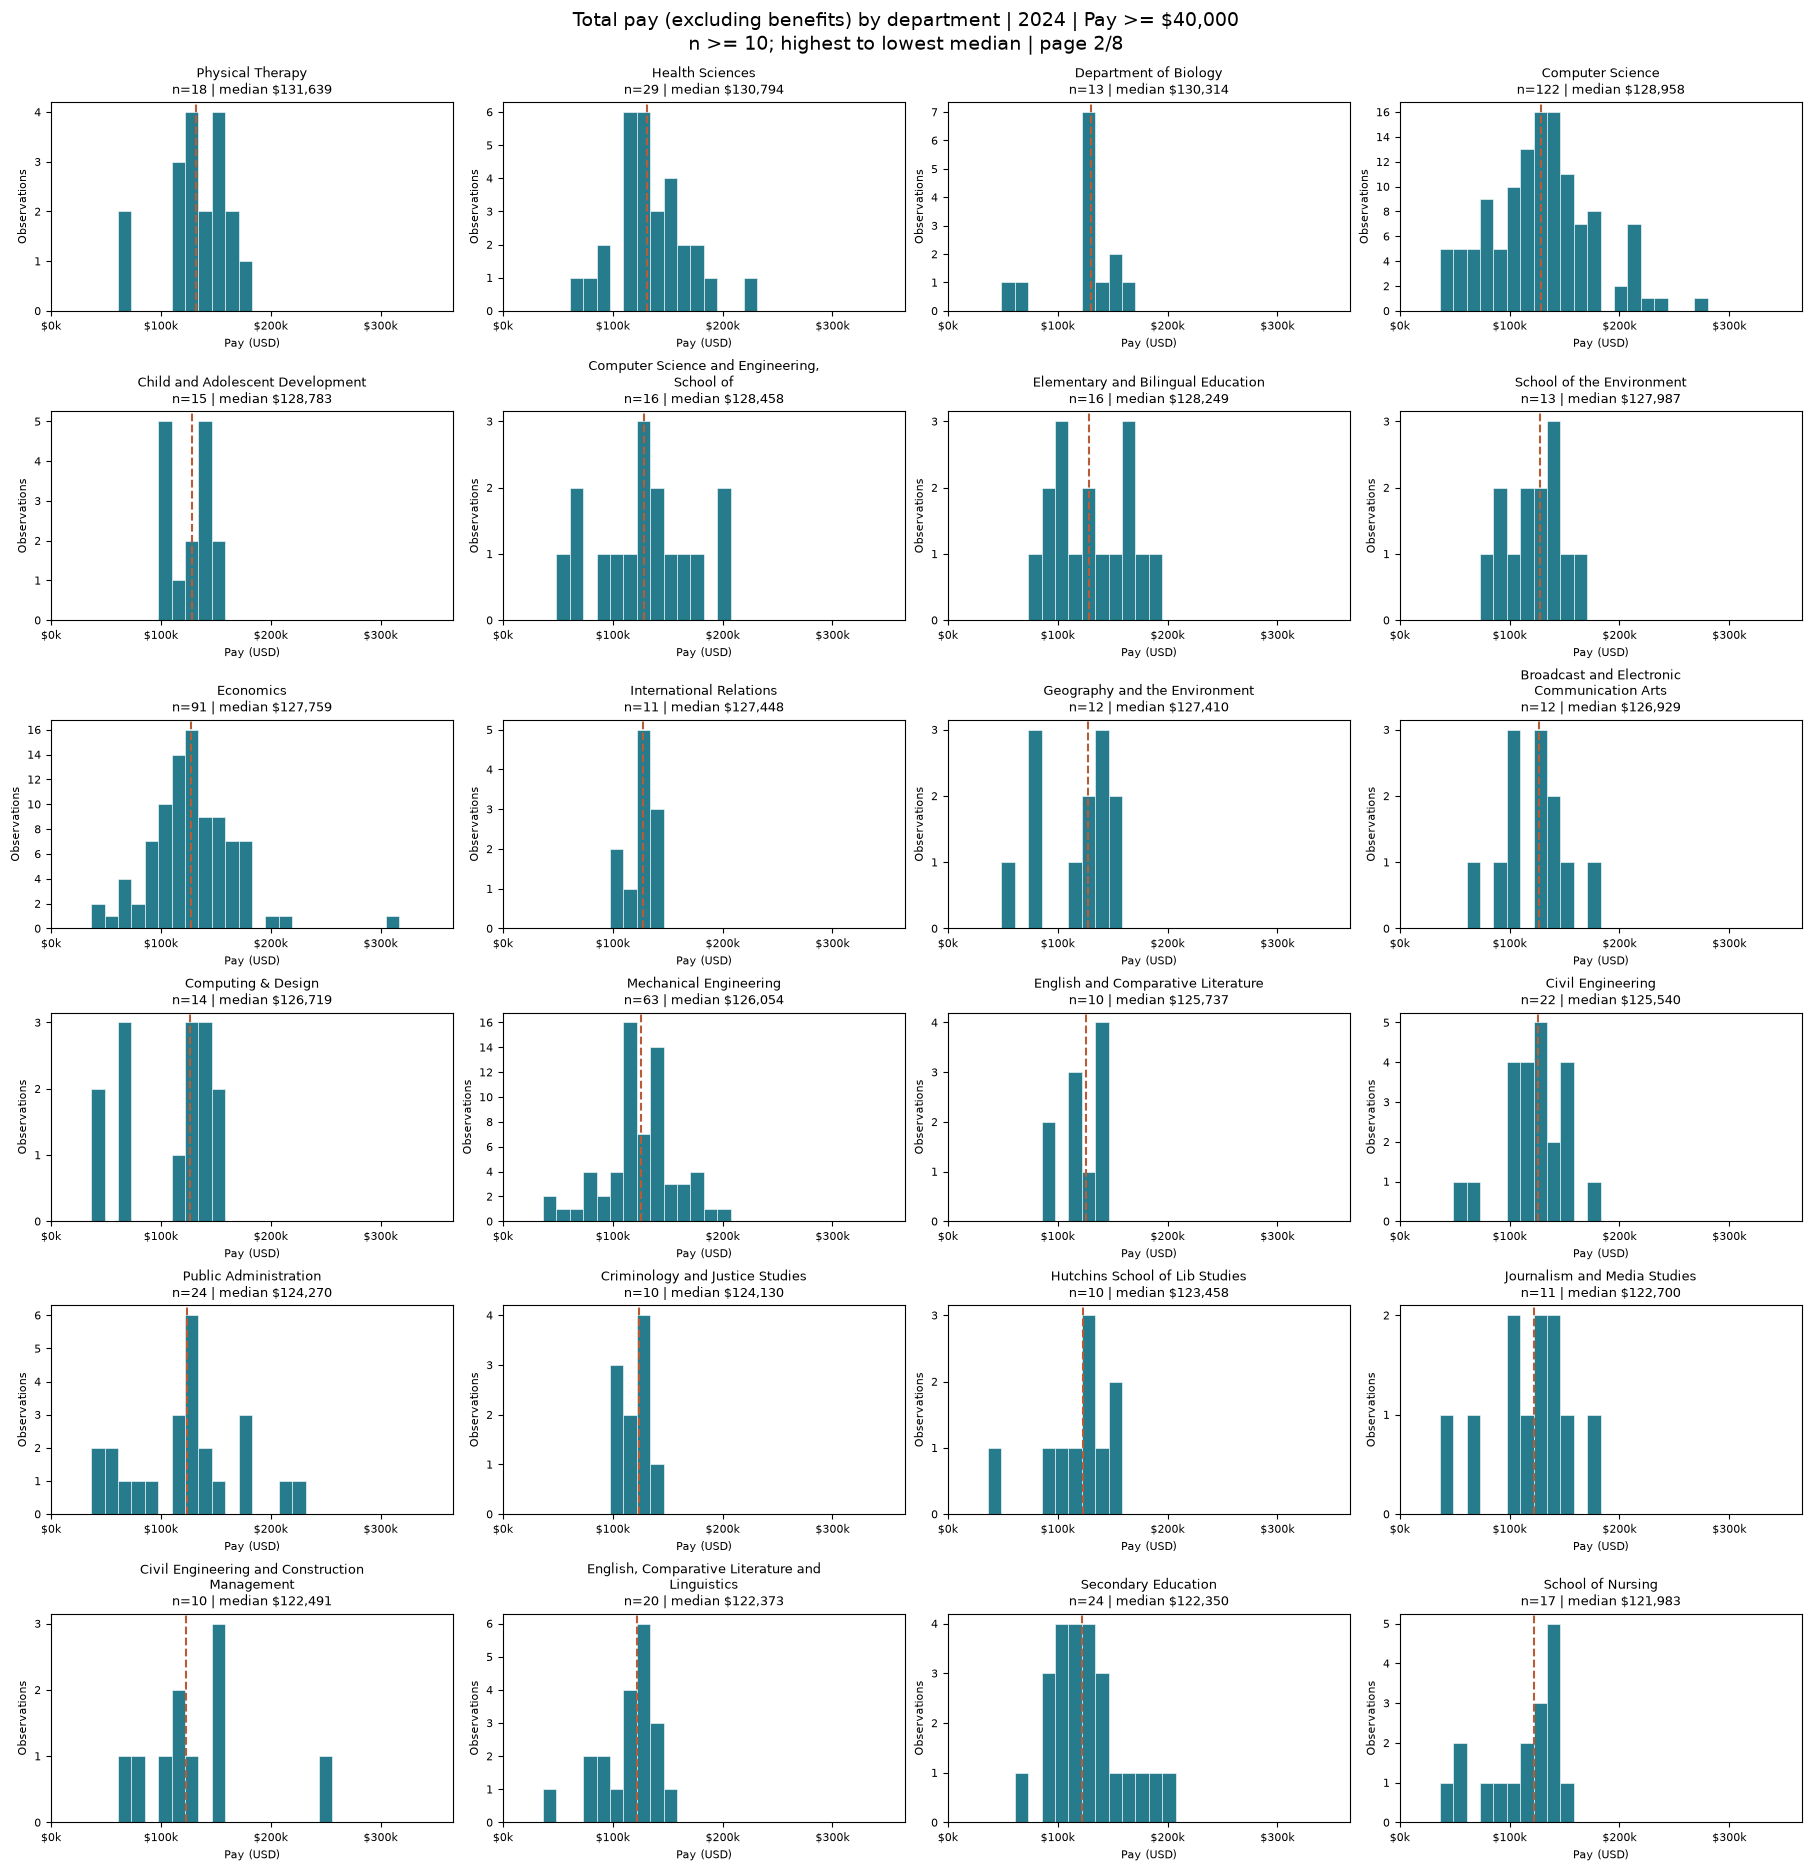

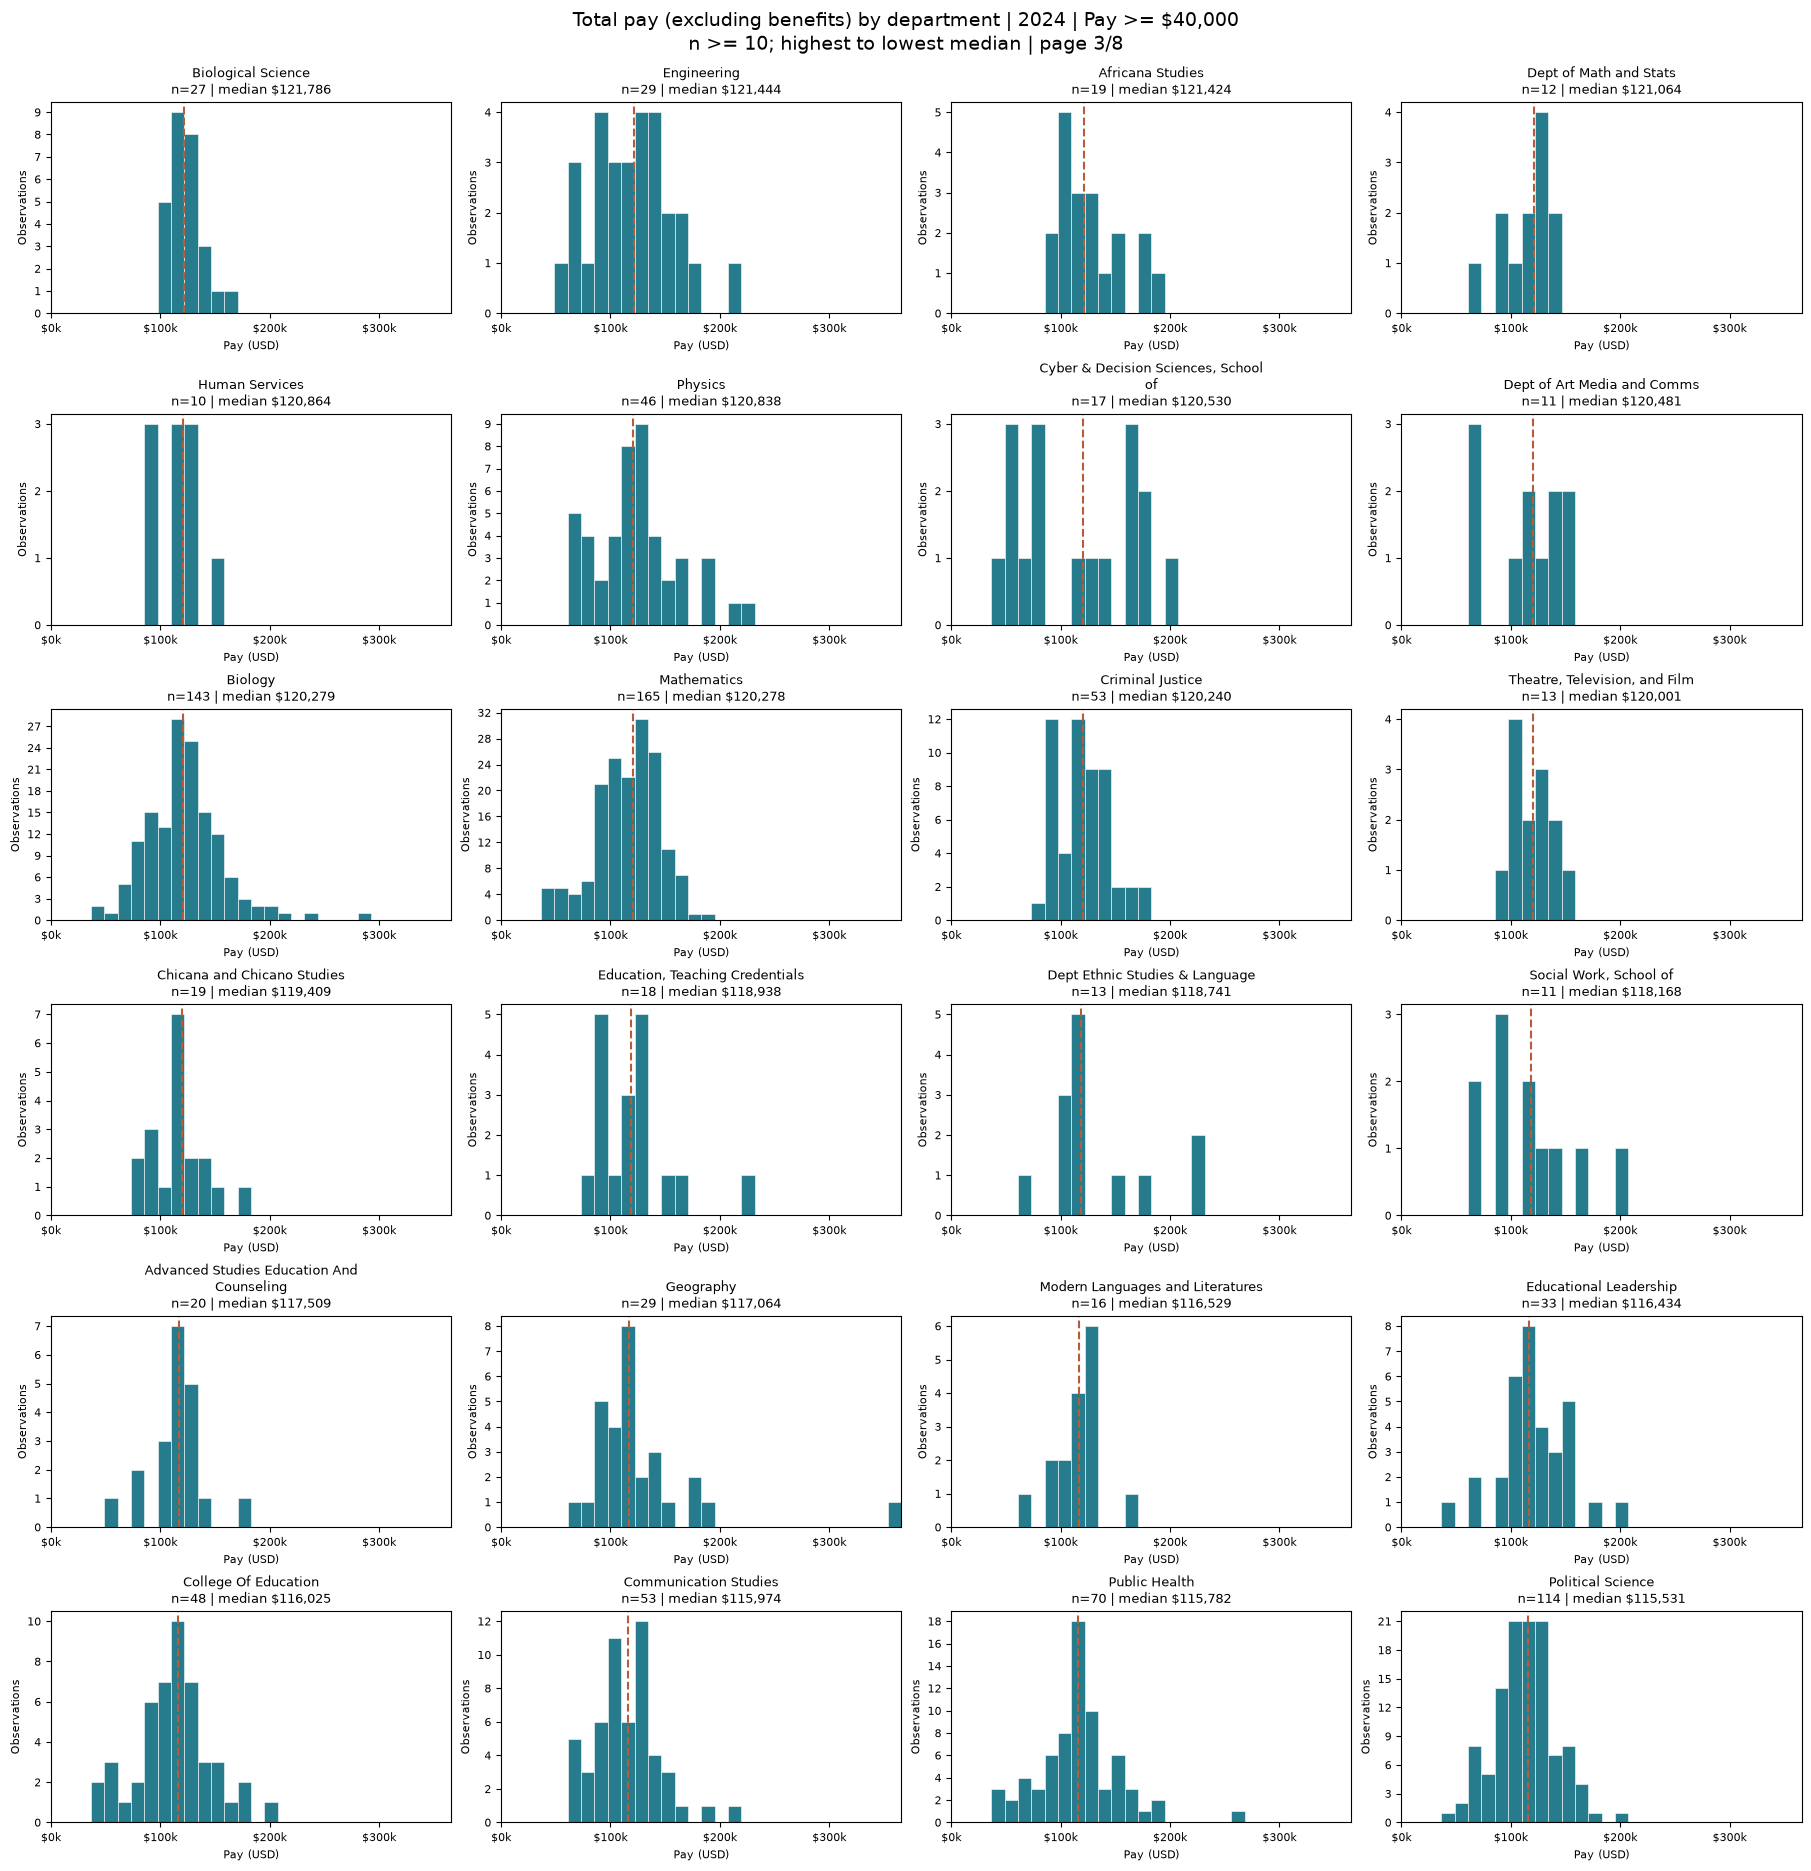

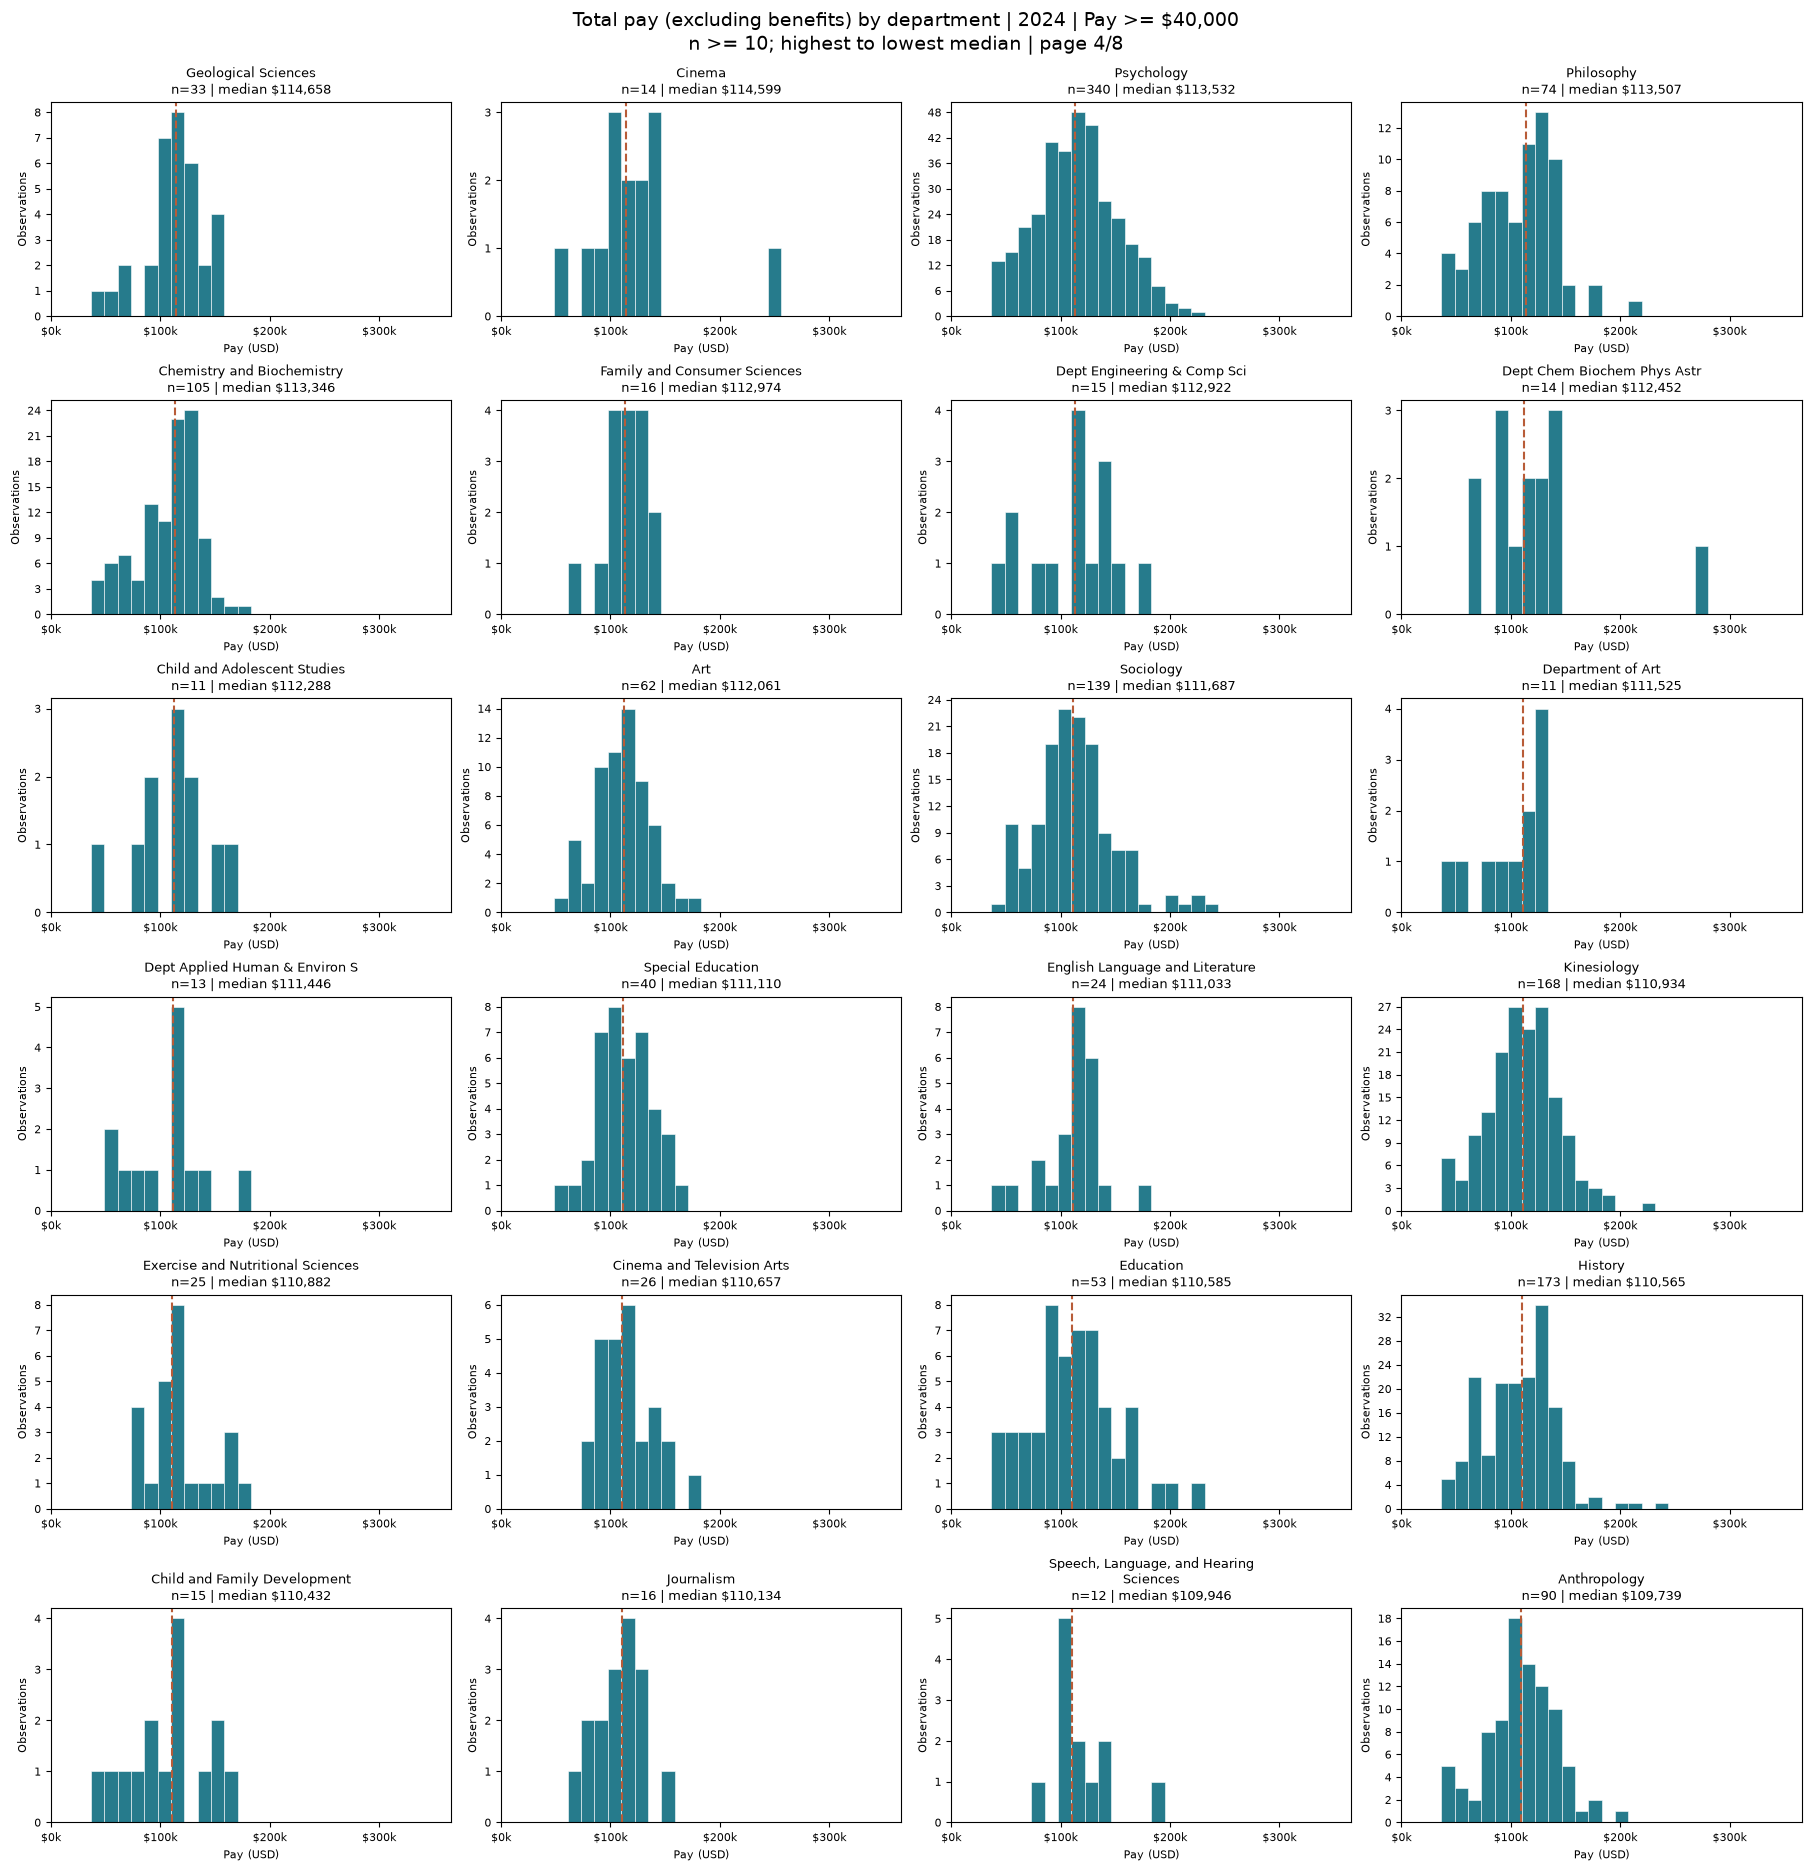

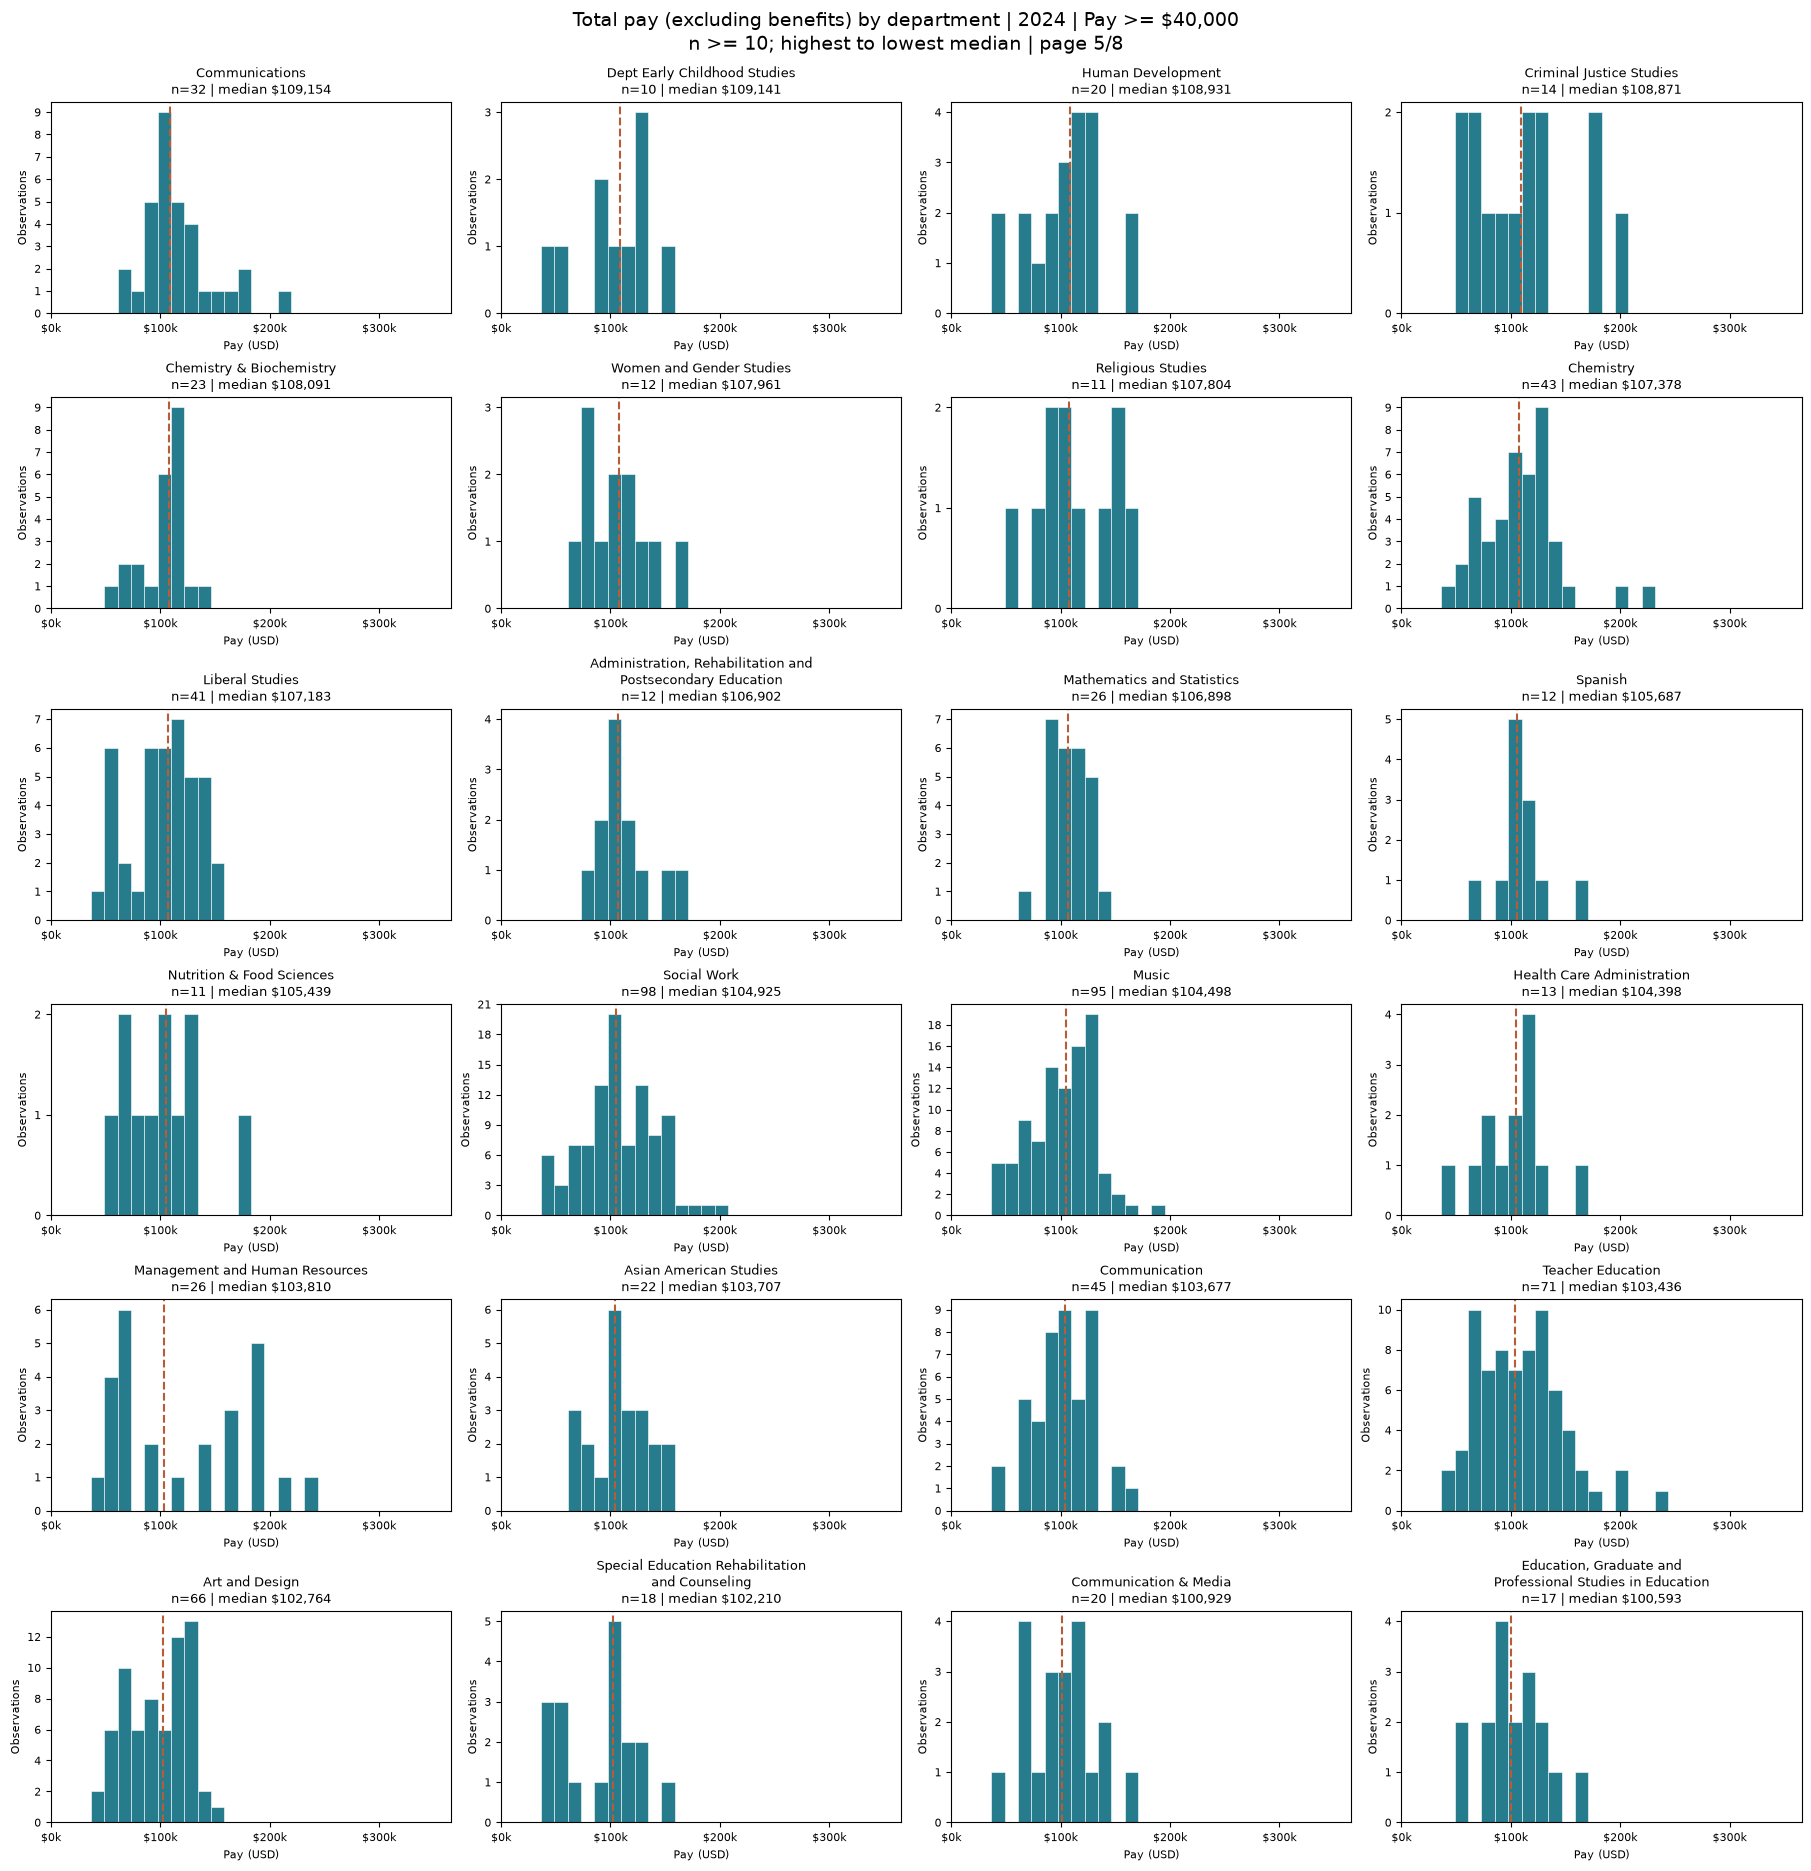

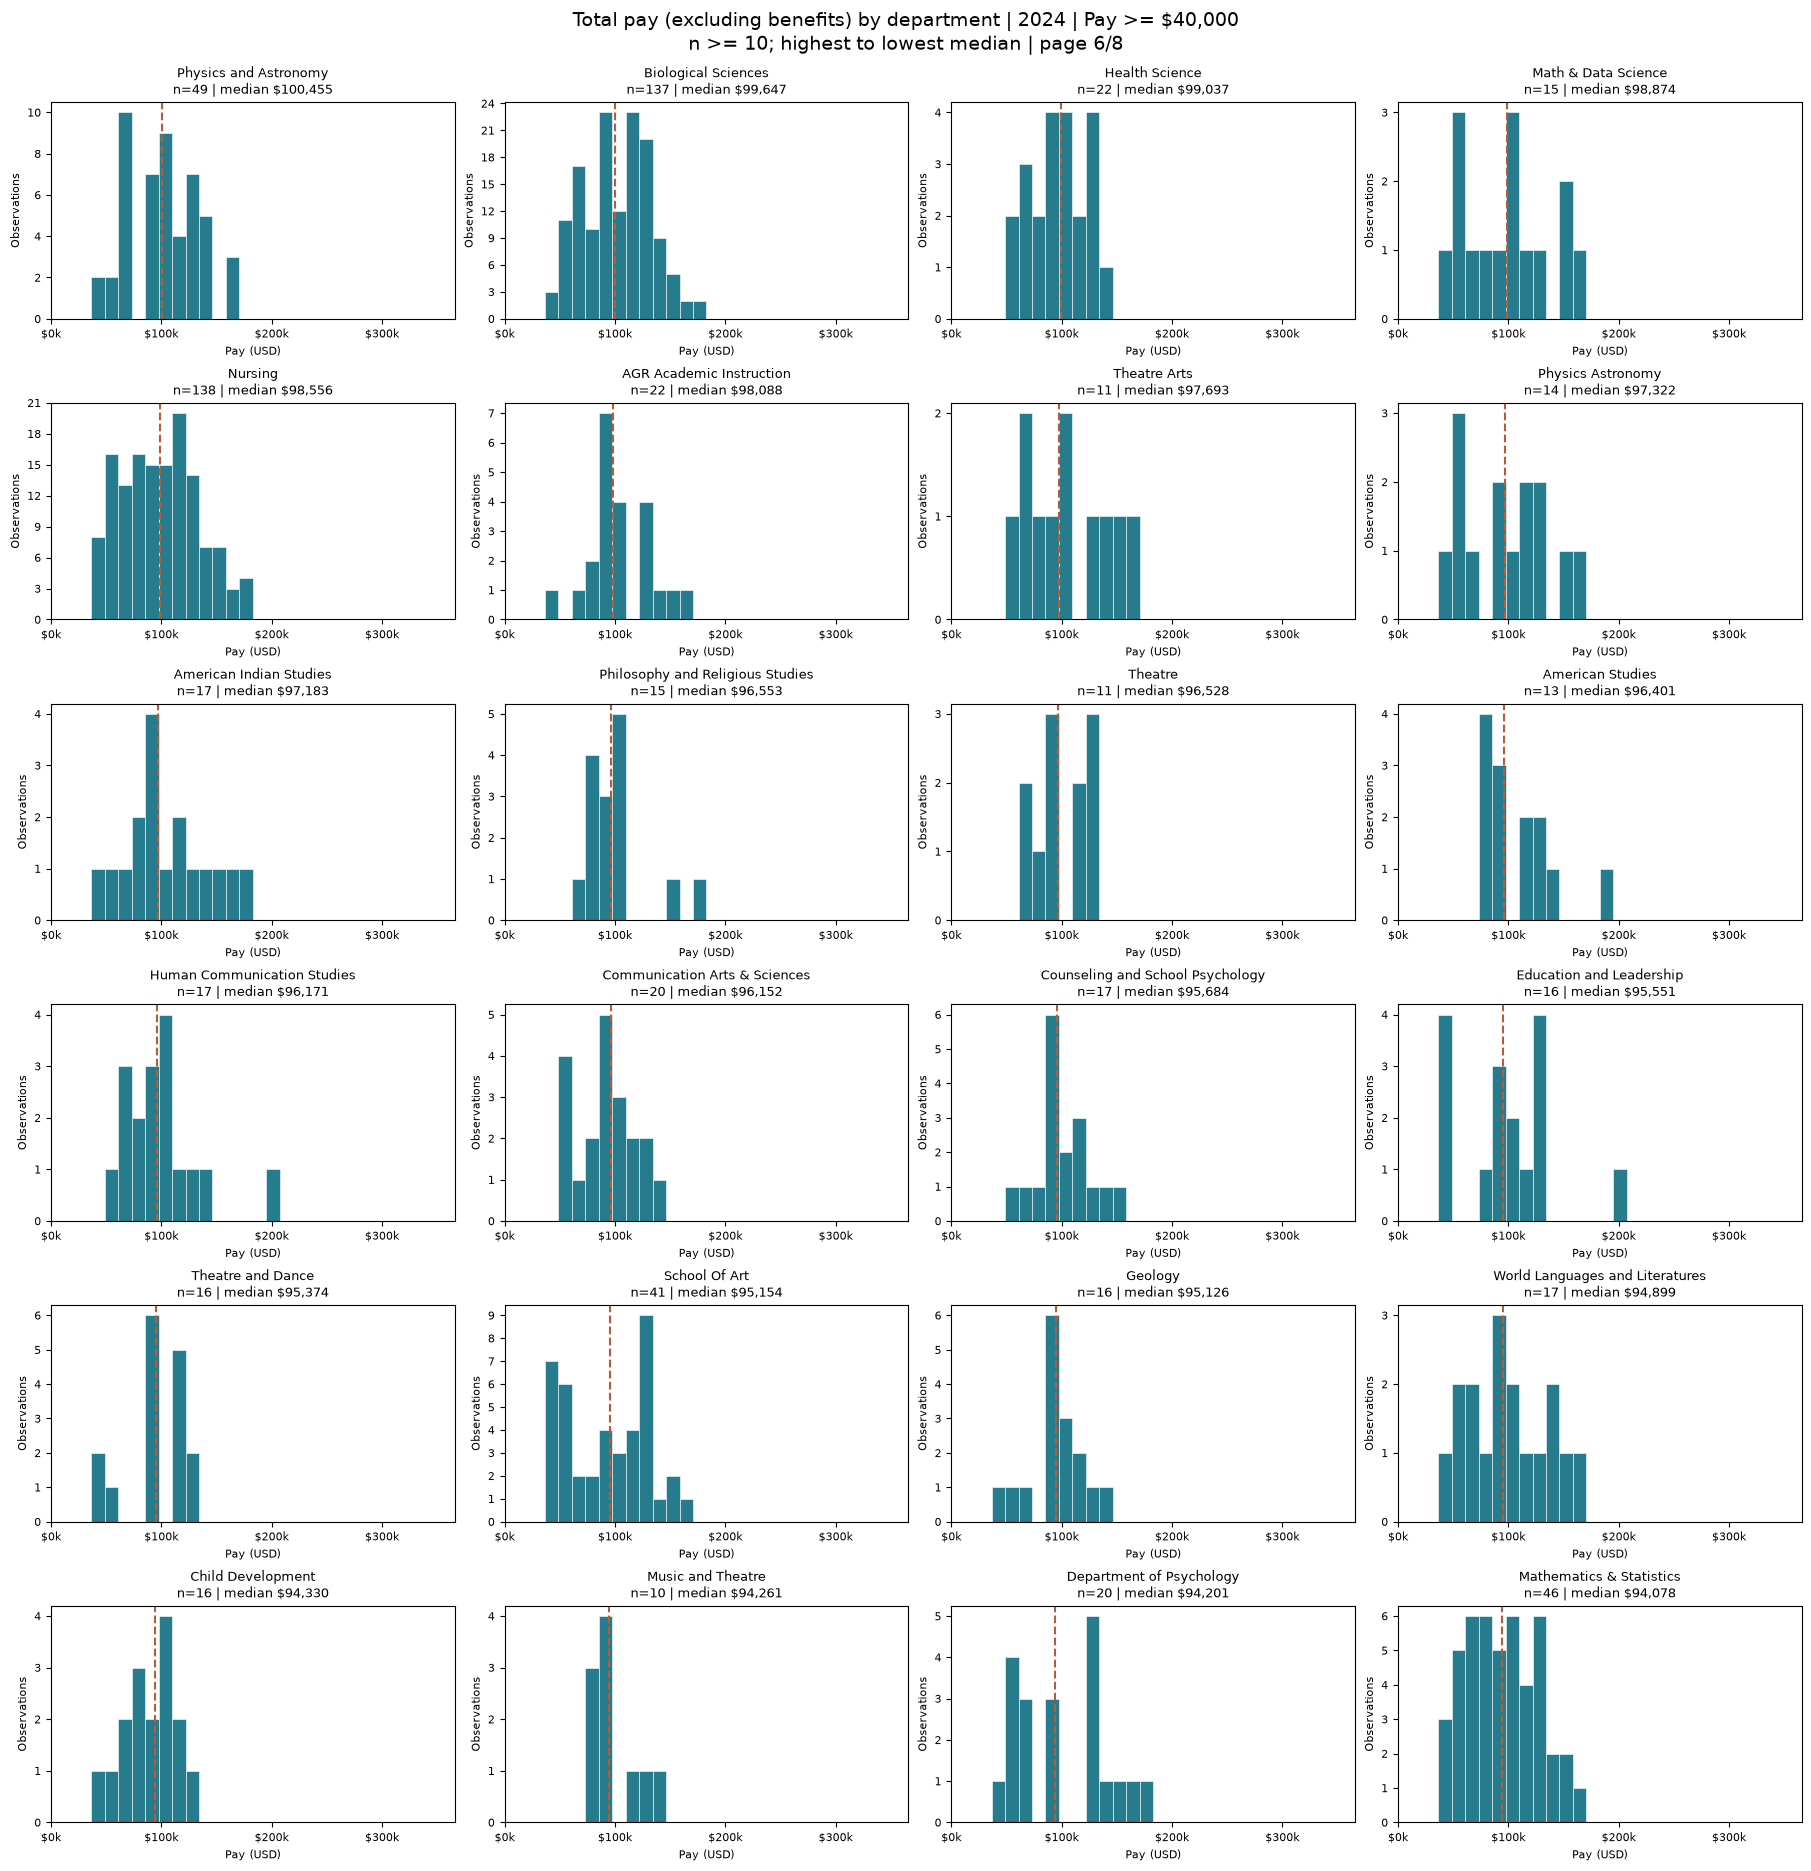

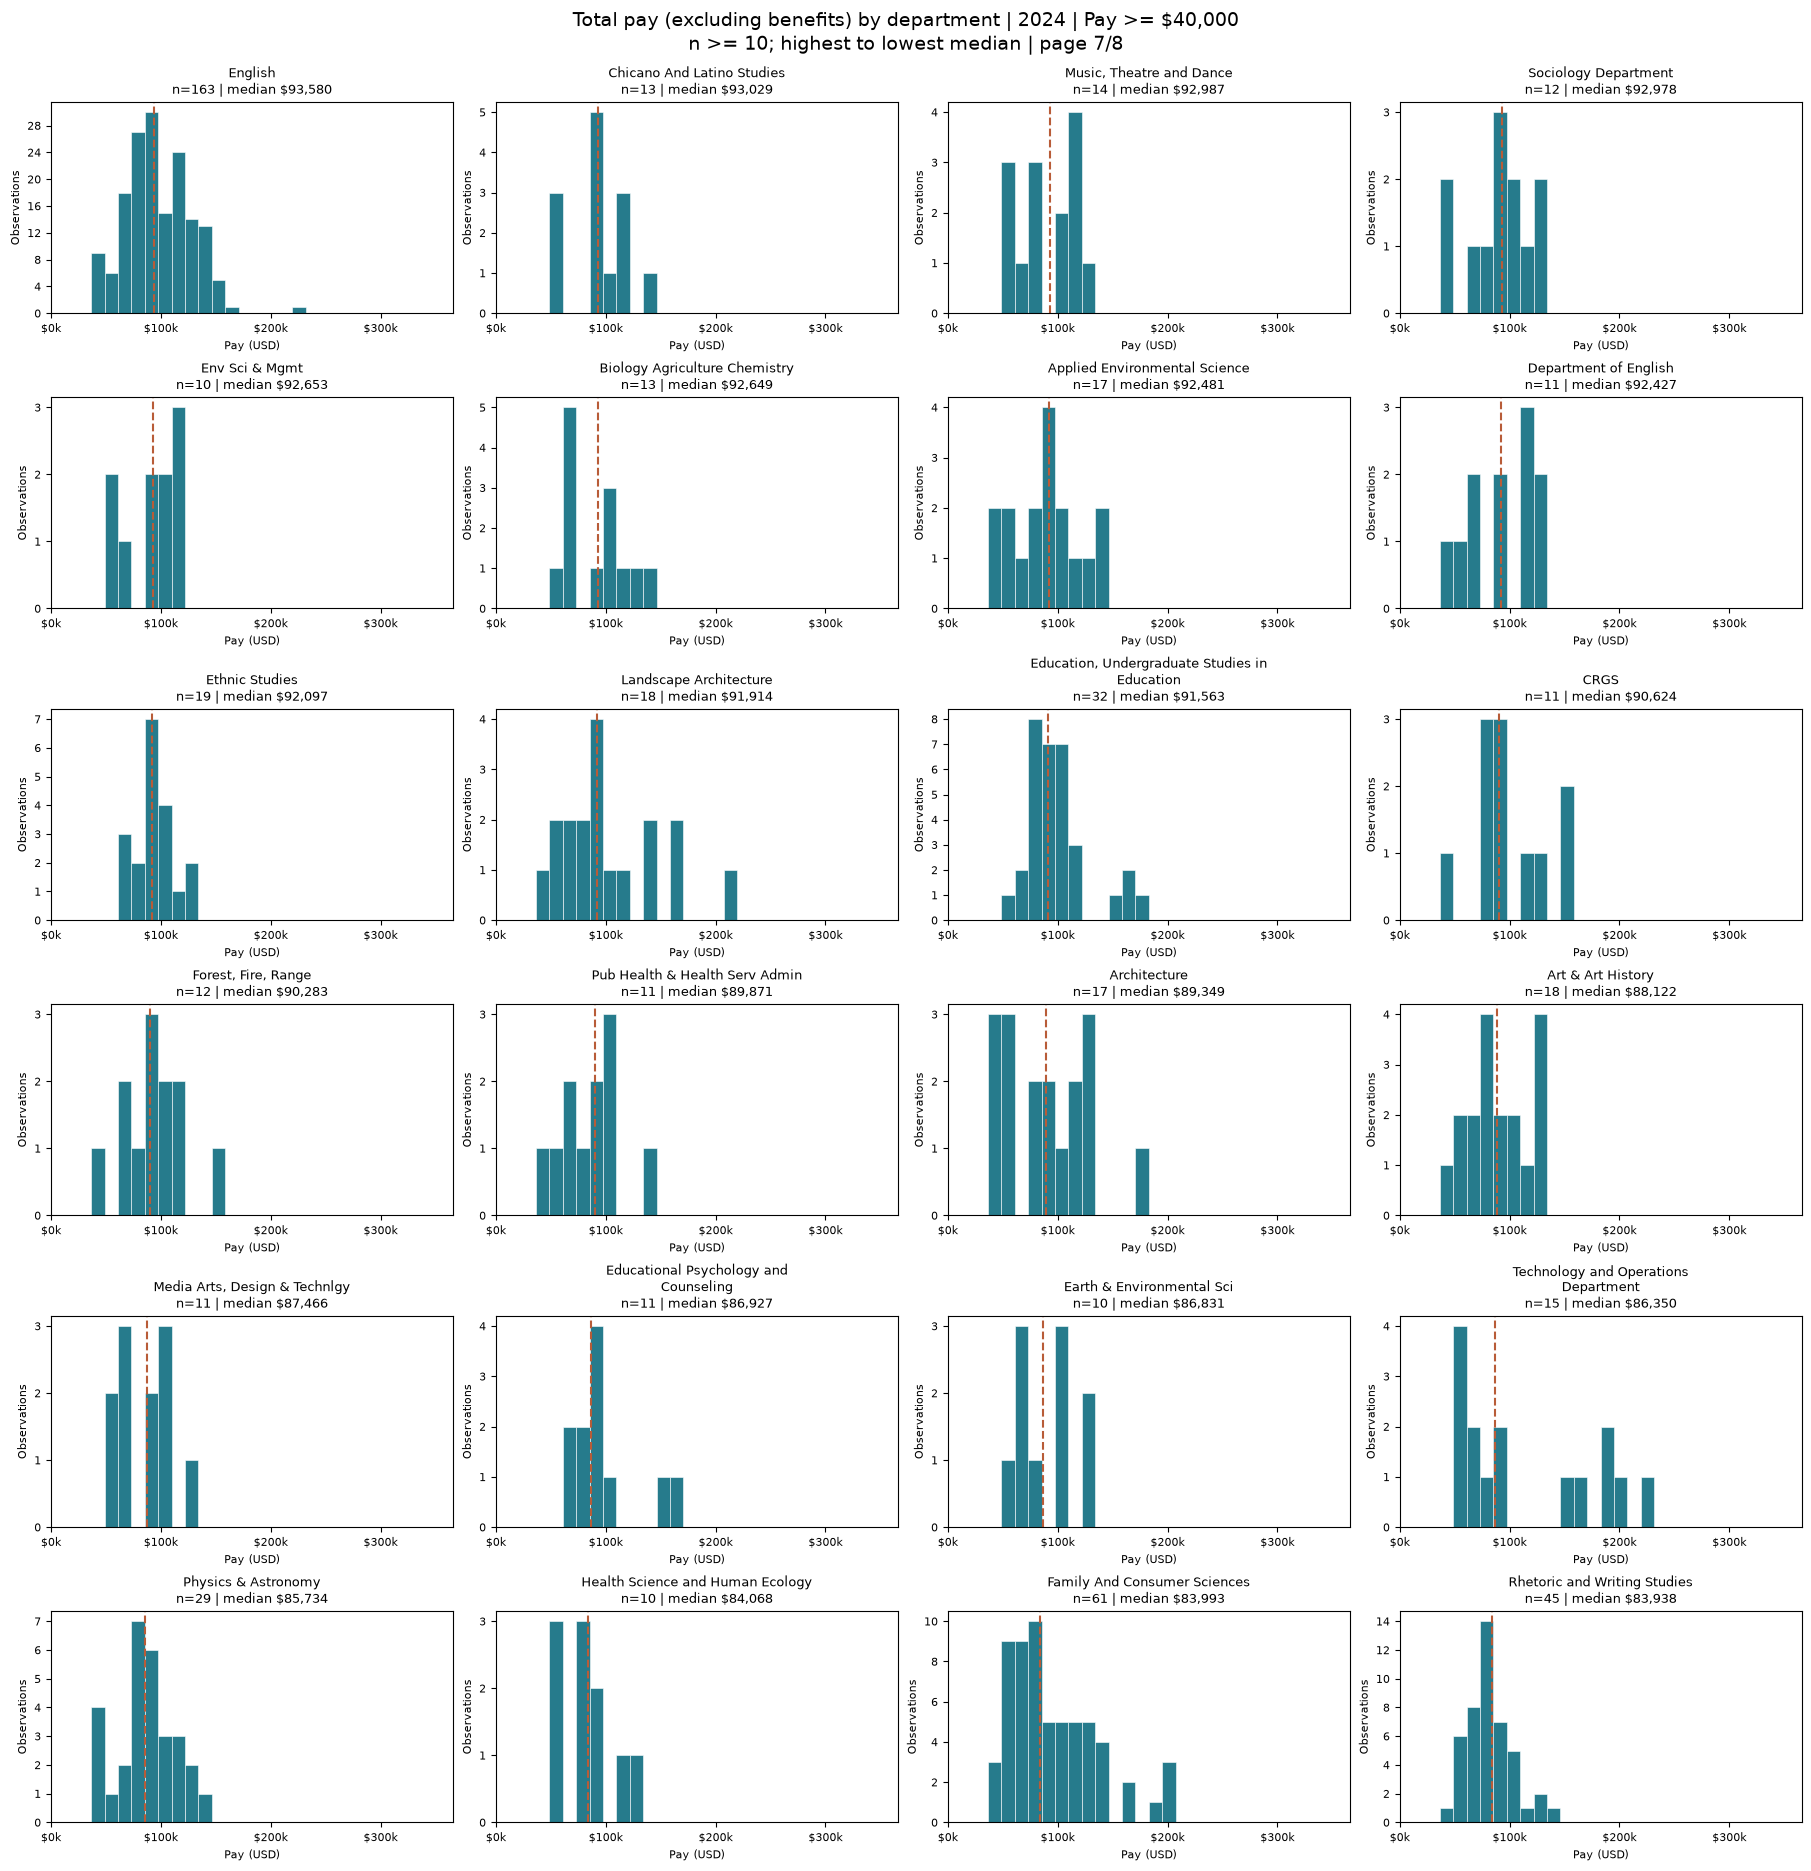

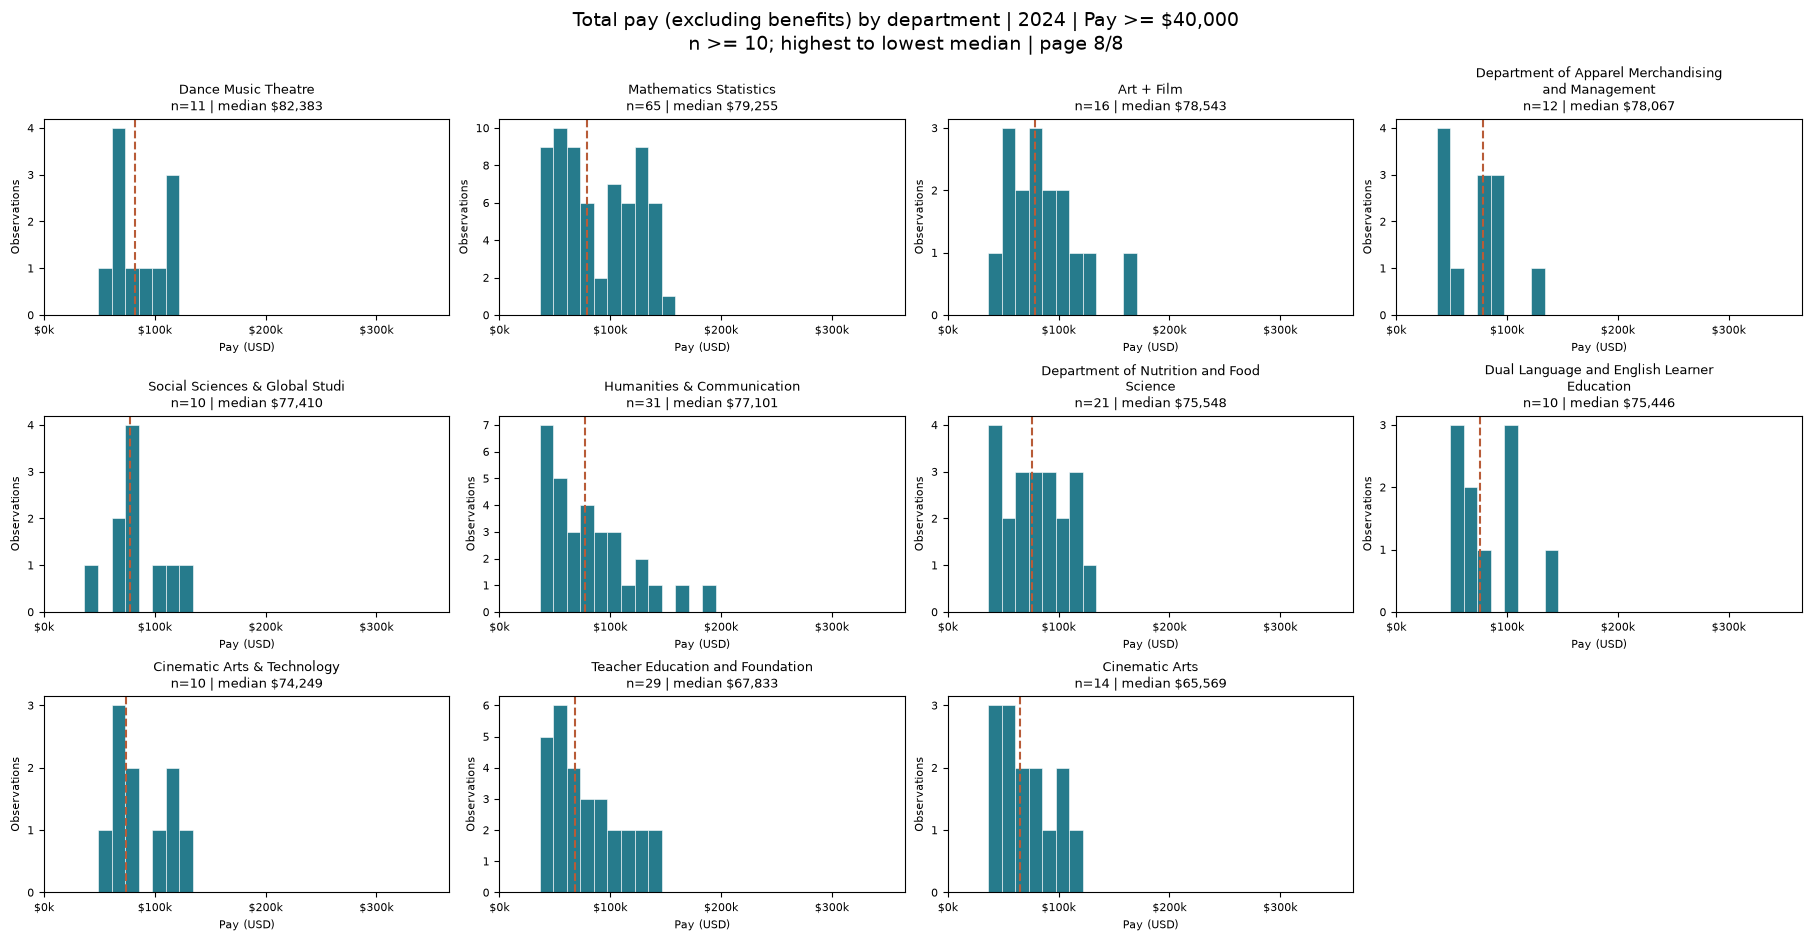

In [11]:
# Common bins make distributions comparable across departments.
upper_pay = float(plot_data["pay"].max())
bin_edges = np.linspace(0, max(upper_pay, 1.0), 31)
departments = summary.index.tolist()
pages = math.ceil(len(departments) / HISTOGRAMS_PER_PAGE)

for start in range(0, len(departments), HISTOGRAMS_PER_PAGE):
    page_departments = departments[start:start + HISTOGRAMS_PER_PAGE]
    rows = math.ceil(len(page_departments) / 4)
    fig, axes = plt.subplots(rows, 4, figsize=(18, rows * 3.1),
                             squeeze=False, sharex=True, layout="constrained")
    for ax, department in zip(axes.flat, page_departments):
        values = plot_data.loc[plot_data["department"].eq(department), "pay"]
        median = summary.loc[department, "median_pay"]
        ax.hist(values, bins=bin_edges, color="#267b8c", edgecolor="white", linewidth=0.4)
        ax.axvline(median, color="#b85c38", linestyle="--", linewidth=1.5)
        ax.set_title(textwrap.fill(department, 35)
                     + f"\nn={len(values):,} | median ${median:,.0f}", fontsize=9)
        ax.set_xlim(bin_edges[0], bin_edges[-1])
        ax.set_xlabel("Pay (USD)", fontsize=8)
        ax.set_ylabel("Observations", fontsize=8)
        ax.xaxis.set_major_locator(MaxNLocator(4))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"${value / 1000:,.0f}k"))
        ax.yaxis.set_major_locator(MaxNLocator(integer=True))
        ax.tick_params(labelsize=8, labelbottom=True)
    for ax in list(axes.flat)[len(page_departments):]:
        ax.set_visible(False)
    page = start // HISTOGRAMS_PER_PAGE + 1
    fig.suptitle(f"{pay_label} by department | {years} | {pay_filter_note}\n"
                 f"n >= {MIN_OBSERVATIONS}; highest to lowest median | page {page}/{pages}", fontsize=14)
    plt.show()
